# Grouped Legislator Stance Volume

| Item | Description |
|---|---|
| Goal | Plot concern and support speech-turn counts for the approved topic groups, ordered by the number of distinct legislator speech turns with either stance. |
| Comparison | Descriptive comparison of concern and support within each group across House Science and Senate Commerce hearings. |
| Unit and sample | One legislator speech turn, identified by hearing `packageId` and `turn_idx`, within a topic group. Only records assigned to a codebook topic are included. |
| Timing | Hearings held in 1999–2025, matching the archived topic-screening figure. The eight assigned records from the single 1996 hearing are excluded by this window. |
| Counting rule | Repeated records within a group, turn, and stance count once. A turn expressing both stances counts in both bars but only once in the sorting total. A turn can contribute to more than one group. |
| Input | `topic_groups.csv` beside this notebook; `interim/topics/taxonomy/track2_assigned.parquet` and `interim/repo_data/raw/02_hearings/hearings_sst.parquet` under `/project2/mmiric_1435/acroh/llm_method/data`. |
| Output | `fig_select_volume_balance_groups.png/.svg/.pdf` and `group_stance_turn_counts.csv`, all in `output/T2.4.1/` beside this notebook. Exact paths appear in Step 2. |
| Variables | • `n_hearings`: $H_g$, distinct hearings with a stance-bearing turn in group $g$.<br>• `stance_turns`: $N_g = \lvert C_g \cup S_g \rvert$, distinct turns with either stance in group $g$; the sorting variable.<br>• `concern_turns`: $\lvert C_g \rvert$, the count of distinct turns with at least one concern record in group $g$.<br>• `support_turns`: $\lvert S_g \rvert$, the count of distinct turns with at least one support record in group $g$.<br>• `both_stance_turns`: $B_g = \lvert C_g \cap S_g \rvert$, distinct turns counted in both bars.<br> |
| Interpretation | Bar lengths are speech-turn counts, not stance-record counts or shares. No sponsor or support-share axis is included. The figure is descriptive. |

The archived reference is `archive/output/T2.4.1 - Step 1 - Topic Screening/fig_select_volume_balance.pdf`. This notebook uses the Python and figure conventions in the supplied `S--Style` guides, adapted to this project's paths and existing upstream data. It uses the `python3` kernel and runs independently from top to bottom.

## Step 1. Import packages

Use pandas for data preparation and Matplotlib for the figure. Markdown and image display keep the caption outside the exported canvas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.transforms import blended_transform_factory
from IPython.display import Image, Markdown, display

## Step 2. Define file locations

Keep all paths independent of the working directory. Read the existing upstream files in place. Save the figure data and all three figure formats in the `output/T2.4.1/` folder beside this notebook.

In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path(
    "T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection"
)

GROUPS_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "topic_groups.csv"
RECORDS_FILE = SOURCE_DATA_FOLDER / "interim/topics/taxonomy/track2_assigned.parquet"
HEARINGS_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/02_hearings/hearings_sst.parquet"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output" / "T2.4.1"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Figure data: {OUTPUT_FOLDER / 'group_stance_turn_counts.csv'}")
print(f"Figure exports: {OUTPUT_FOLDER}")

Figure data: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.1/group_stance_turn_counts.csv
Figure exports: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.1


## Step 3. Apply the figure style

Use a fixed 9-by-6-inch white canvas, serif text, named colors, and horizontal background lines. Concern is red and support is blue. Use DejaVu Serif for bold text because the installed Times New Roman font has no bold face. Figure captions remain outside the image.

In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BOLD_TEXT = {"fontweight": "bold", "fontfamily": "DejaVu Serif"}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 9
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

## Step 4. Load the approved topic groups

Each codebook topic must belong to exactly one group. Use every group in the mapping, including any with zero qualifying turns.

In [4]:
topic_groups = pd.read_csv(GROUPS_FILE, usecols=["group", "label", "topic_id"])
assert topic_groups.notna().all().all(), "The topic mapping contains missing values."
assert topic_groups["topic_id"].is_unique, "A topic is assigned to more than one group."
assert topic_groups["group"].str.strip().ne("").all(), "A group name is empty."
print(f"Topic mappings: {len(topic_groups):,}; groups: {topic_groups['group'].nunique():,}")
display(topic_groups.head(3))

Topic mappings: 111; groups: 26


,group,label,topic_id
0,NASA and space policy,International Space Station,4
1,NASA and space policy,Commercial Crew Program,9
2,NASA and space policy,Mars and lunar exploration missions,10


## Step 5. Load legislator stance records

The upstream Track 2 file contains positions extracted from legislator speech turns. Load only the fields needed for grouping and counting. Check legislator identifiers and the hearing/turn key; repeated stance records are retained until the group mapping is attached.

In [5]:
records = pd.read_parquet(
    RECORDS_FILE,
    columns=["packageId", "turn_idx", "bioGuideId", "topic_id", "stance"],
)
assert records.notna().all().all(), "A required stance-record field is missing."
assert records["stance"].isin(["concern", "support"]).all(), "An unexpected stance is present."
legislators_per_turn = records.groupby(["packageId", "turn_idx"])["bioGuideId"].nunique()
assert legislators_per_turn.eq(1).all(), "A speech-turn key identifies multiple legislators."
print(f"Extracted legislator stance records: {len(records):,}")
display(records.head(3))

Extracted legislator stance records: 32,385


,packageId,turn_idx,bioGuideId,topic_id,stance
0,CHRG-104hhrg37345,33,R000409,86,concern
1,CHRG-104hhrg37345,33,R000409,90,concern
2,CHRG-104hhrg37345,33,R000409,110,support


## Step 6. Load hearing dates

Use the date the hearing was held rather than a publication or extraction year. Read only the identifier and date from the hearing file.

In [6]:
hearings = pd.read_parquet(HEARINGS_FILE, columns=["packageId", "heldDate_first"])
assert hearings["packageId"].is_unique, "Hearing identifiers must be unique."
print(f"Hearing metadata rows: {len(hearings):,}")
display(hearings.head(3))

Hearing metadata rows: 2,352


,packageId,heldDate_first
0,CHRG-104hhrg37345,1996-08-01
1,CHRG-105hhrg38882,1997-02-12
2,CHRG-106hhrg58508,1999-07-13


## Step 7. Keep records assigned to codebook topics

Negative topic identifiers represent unassigned records. Exclude them before joining the approved mapping, matching the archived screening sample.

In [7]:
assigned_records = records.loc[records["topic_id"].ge(0)].copy()
print(f"Assigned stance records: {len(assigned_records):,}")
print(f"Unassigned records excluded: {len(records) - len(assigned_records):,}")
display(assigned_records.head(3))

Assigned stance records: 29,979
Unassigned records excluded: 2,406


,packageId,turn_idx,bioGuideId,topic_id,stance
0,CHRG-104hhrg37345,33,R000409,86,concern
1,CHRG-104hhrg37345,33,R000409,90,concern
2,CHRG-104hhrg37345,33,R000409,110,support


## Step 8. Attach topic groups

Use a many-to-one join so each stance record receives one group without multiplying records. Stop if any assigned topic is absent from the approved mapping.

In [8]:
grouped_records = assigned_records.merge(
    topic_groups[["topic_id", "group"]],
    on="topic_id",
    how="left",
    validate="many_to_one",
)
assert len(grouped_records) == len(assigned_records)
assert grouped_records["group"].notna().all(), "An assigned topic has no group."
print(f"Grouped stance records: {len(grouped_records):,}")
display(grouped_records.head(3))

Grouped stance records: 29,979


,packageId,turn_idx,bioGuideId,topic_id,stance,group
0,CHRG-104hhrg37345,33,R000409,86,concern,Homeland and transportation security
1,CHRG-104hhrg37345,33,R000409,90,concern,Competition and intellectual property
2,CHRG-104hhrg37345,33,R000409,110,support,"Science agencies, advisory bodies, and integrity"


## Step 9. Attach hearing years

Join each record to its hearing date. Missing dates are an error rather than a reason to silently drop observations.

In [9]:
dated_records = grouped_records.merge(
    hearings, on="packageId", how="left", validate="many_to_one"
)
assert len(dated_records) == len(grouped_records)
assert dated_records["heldDate_first"].notna().all(), "A stance record has no hearing date."
dated_records["hearing_year"] = pd.to_datetime(dated_records["heldDate_first"]).dt.year
print(f"Dated stance records: {len(dated_records):,}")
display(dated_records.head(3))

Dated stance records: 29,979


,packageId,turn_idx,bioGuideId,topic_id,stance,group,heldDate_first,hearing_year
0,CHRG-104hhrg37345,33,R000409,86,concern,Homeland and transportation security,1996-08-01,1996
1,CHRG-104hhrg37345,33,R000409,90,concern,Competition and intellectual property,1996-08-01,1996
2,CHRG-104hhrg37345,33,R000409,110,support,"Science agencies, advisory bodies, and integrity",1996-08-01,1996


## Step 10. Apply the original hearing-year window

Retain hearings held in 1999–2025 so the new grouping uses the original figure's sample. Print the number excluded by the date restriction.

In [10]:
YEAR_MIN = 1999
YEAR_MAX = 2025
sample_records = dated_records.loc[
    dated_records["hearing_year"].between(YEAR_MIN, YEAR_MAX)
].copy()
assert not sample_records.empty, "No stance records remain in the selected window."
print(f"Stance records in {YEAR_MIN}–{YEAR_MAX}: {len(sample_records):,}")
print(f"Records outside the window: {len(dated_records) - len(sample_records):,}")
display(sample_records.head(3))

Stance records in 1999–2025: 29,971
Records outside the window: 8


,packageId,turn_idx,bioGuideId,topic_id,stance,group,heldDate_first,hearing_year
6,CHRG-106hhrg58508,132,H000067,23,concern,"Energy policy, research, and clean technologies",1999-07-13,1999
7,CHRG-106hhrg60491,123,H000789,139,concern,Consumer and financial protection,1999-01-20,1999
8,CHRG-106hhrg60621,1,H000789,73,concern,Cybersecurity and system integrity,1999-03-02,1999


## Step 11. Identify distinct speech turns within each group and stance

A legislator can make several statements about several component topics in one speech turn. Count that turn once per group and stance. Keep both observations when the turn expresses both concern and support within the group.

In [11]:
group_turn_keys = ["group", "packageId", "turn_idx"]
group_turn_stances = sample_records.drop_duplicates(group_turn_keys + ["stance"])
unique_group_turns = group_turn_stances.drop_duplicates(group_turn_keys)
unique_speech_turns = unique_group_turns.drop_duplicates(["packageId", "turn_idx"])
print(f"Distinct group-turn-stance observations: {len(group_turn_stances):,}")
print(f"Distinct group-turn observations: {len(unique_group_turns):,}")
print(f"Unique legislator speech turns across all groups: {len(unique_speech_turns):,}")
display(group_turn_stances[["group", "packageId", "turn_idx", "stance"]].head(3))

Distinct group-turn-stance observations: 21,491
Distinct group-turn observations: 19,908
Unique legislator speech turns across all groups: 12,638


,group,packageId,turn_idx,stance
6,"Energy policy, research, and clean technologies",CHRG-106hhrg58508,132,concern
7,Consumer and financial protection,CHRG-106hhrg60491,123,concern
8,Cybersecurity and system integrity,CHRG-106hhrg60621,1,concern


## Step 12. Count and rank the groups

Count concern and support separately. Rank groups by distinct speech turns with either stance, largest first, using the group name to break ties. The overlap count verifies that adding the two bars would double-count mixed-stance turns.

Also count distinct hearings with at least one stance-bearing turn in each group.

In [12]:
group_counts = group_turn_stances.groupby(["group", "stance"]).size().unstack(fill_value=0)
group_counts = group_counts.reindex(
    index=topic_groups["group"].drop_duplicates(),
    columns=["concern", "support"],
    fill_value=0,
)
group_counts = group_counts.rename(
    columns={"concern": "concern_turns", "support": "support_turns"}
)
group_counts.columns.name = None
turn_totals = unique_group_turns.groupby("group").size()
group_counts["stance_turns"] = turn_totals.reindex(group_counts.index, fill_value=0)
hearing_totals = unique_group_turns.groupby("group")["packageId"].nunique()
group_counts["n_hearings"] = hearing_totals.reindex(group_counts.index, fill_value=0)
group_counts["both_stance_turns"] = (
    group_counts["concern_turns"] + group_counts["support_turns"] - group_counts["stance_turns"]
)
group_counts = group_counts.reset_index()
group_counts = group_counts.sort_values(["stance_turns", "group"], ascending=[False, True])
group_counts = group_counts.reset_index(drop=True)

assert len(group_counts) == topic_groups["group"].nunique()
assert group_counts["stance_turns"].is_monotonic_decreasing
assert group_counts["n_hearings"].le(group_counts["stance_turns"]).all()
assert group_counts["stance_turns"].sum() == len(unique_group_turns)
assert group_counts[["concern_turns", "support_turns"]].to_numpy().sum() == len(group_turn_stances)
assert group_counts["both_stance_turns"].ge(0).all()
assert group_counts["both_stance_turns"].le(
    group_counts[["concern_turns", "support_turns"]].min(axis=1)
).all()
print(f"Groups ranked: {len(group_counts):,}")
print(f"Group-turns expressing both stances: {group_counts['both_stance_turns'].sum():,}")
display(group_counts.head(3))

Groups ranked: 26
Group-turns expressing both stances: 1,583


,group,concern_turns,support_turns,stance_turns,n_hearings,both_stance_turns
0,"Federal budgets, appropriations, and stimulus",851,805,1558,864,98
1,Homeland and transportation security,739,628,1285,752,82
2,"Energy policy, research, and clean technologies",582,748,1204,460,126


## Step 13. Save the figure data

Save the sorted counts and overlap diagnostic as a data CSV in the output folder beside this notebook. This preserves the numbers behind the figure without adding another exhibit.

In [13]:
counts_file = OUTPUT_FOLDER / "group_stance_turn_counts.csv"
group_counts.to_csv(counts_file, index=False)
print(f"Saved: {counts_file}")

Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.1/group_stance_turn_counts.csv


## Step 14. Draw the concern and support bars

Place the topic group, number of distinct hearings, and number of distinct stance-bearing legislator turns in aligned columns before the bars. Bold the column headings and the privacy group's label and counts. Keep the largest groups at the top, with concern left of zero and support right of zero. Export a single fixed-size panel in all three formats and show concise definitions below the figure, following the Track 2 prompt in `T2.X - Background Helper Functions/stance.py` and Appendix A.2 of `Proposal_for_Org_Sci_101126_AR.md`.

**Figure 1. Legislator Concern and Support by Topic Group**

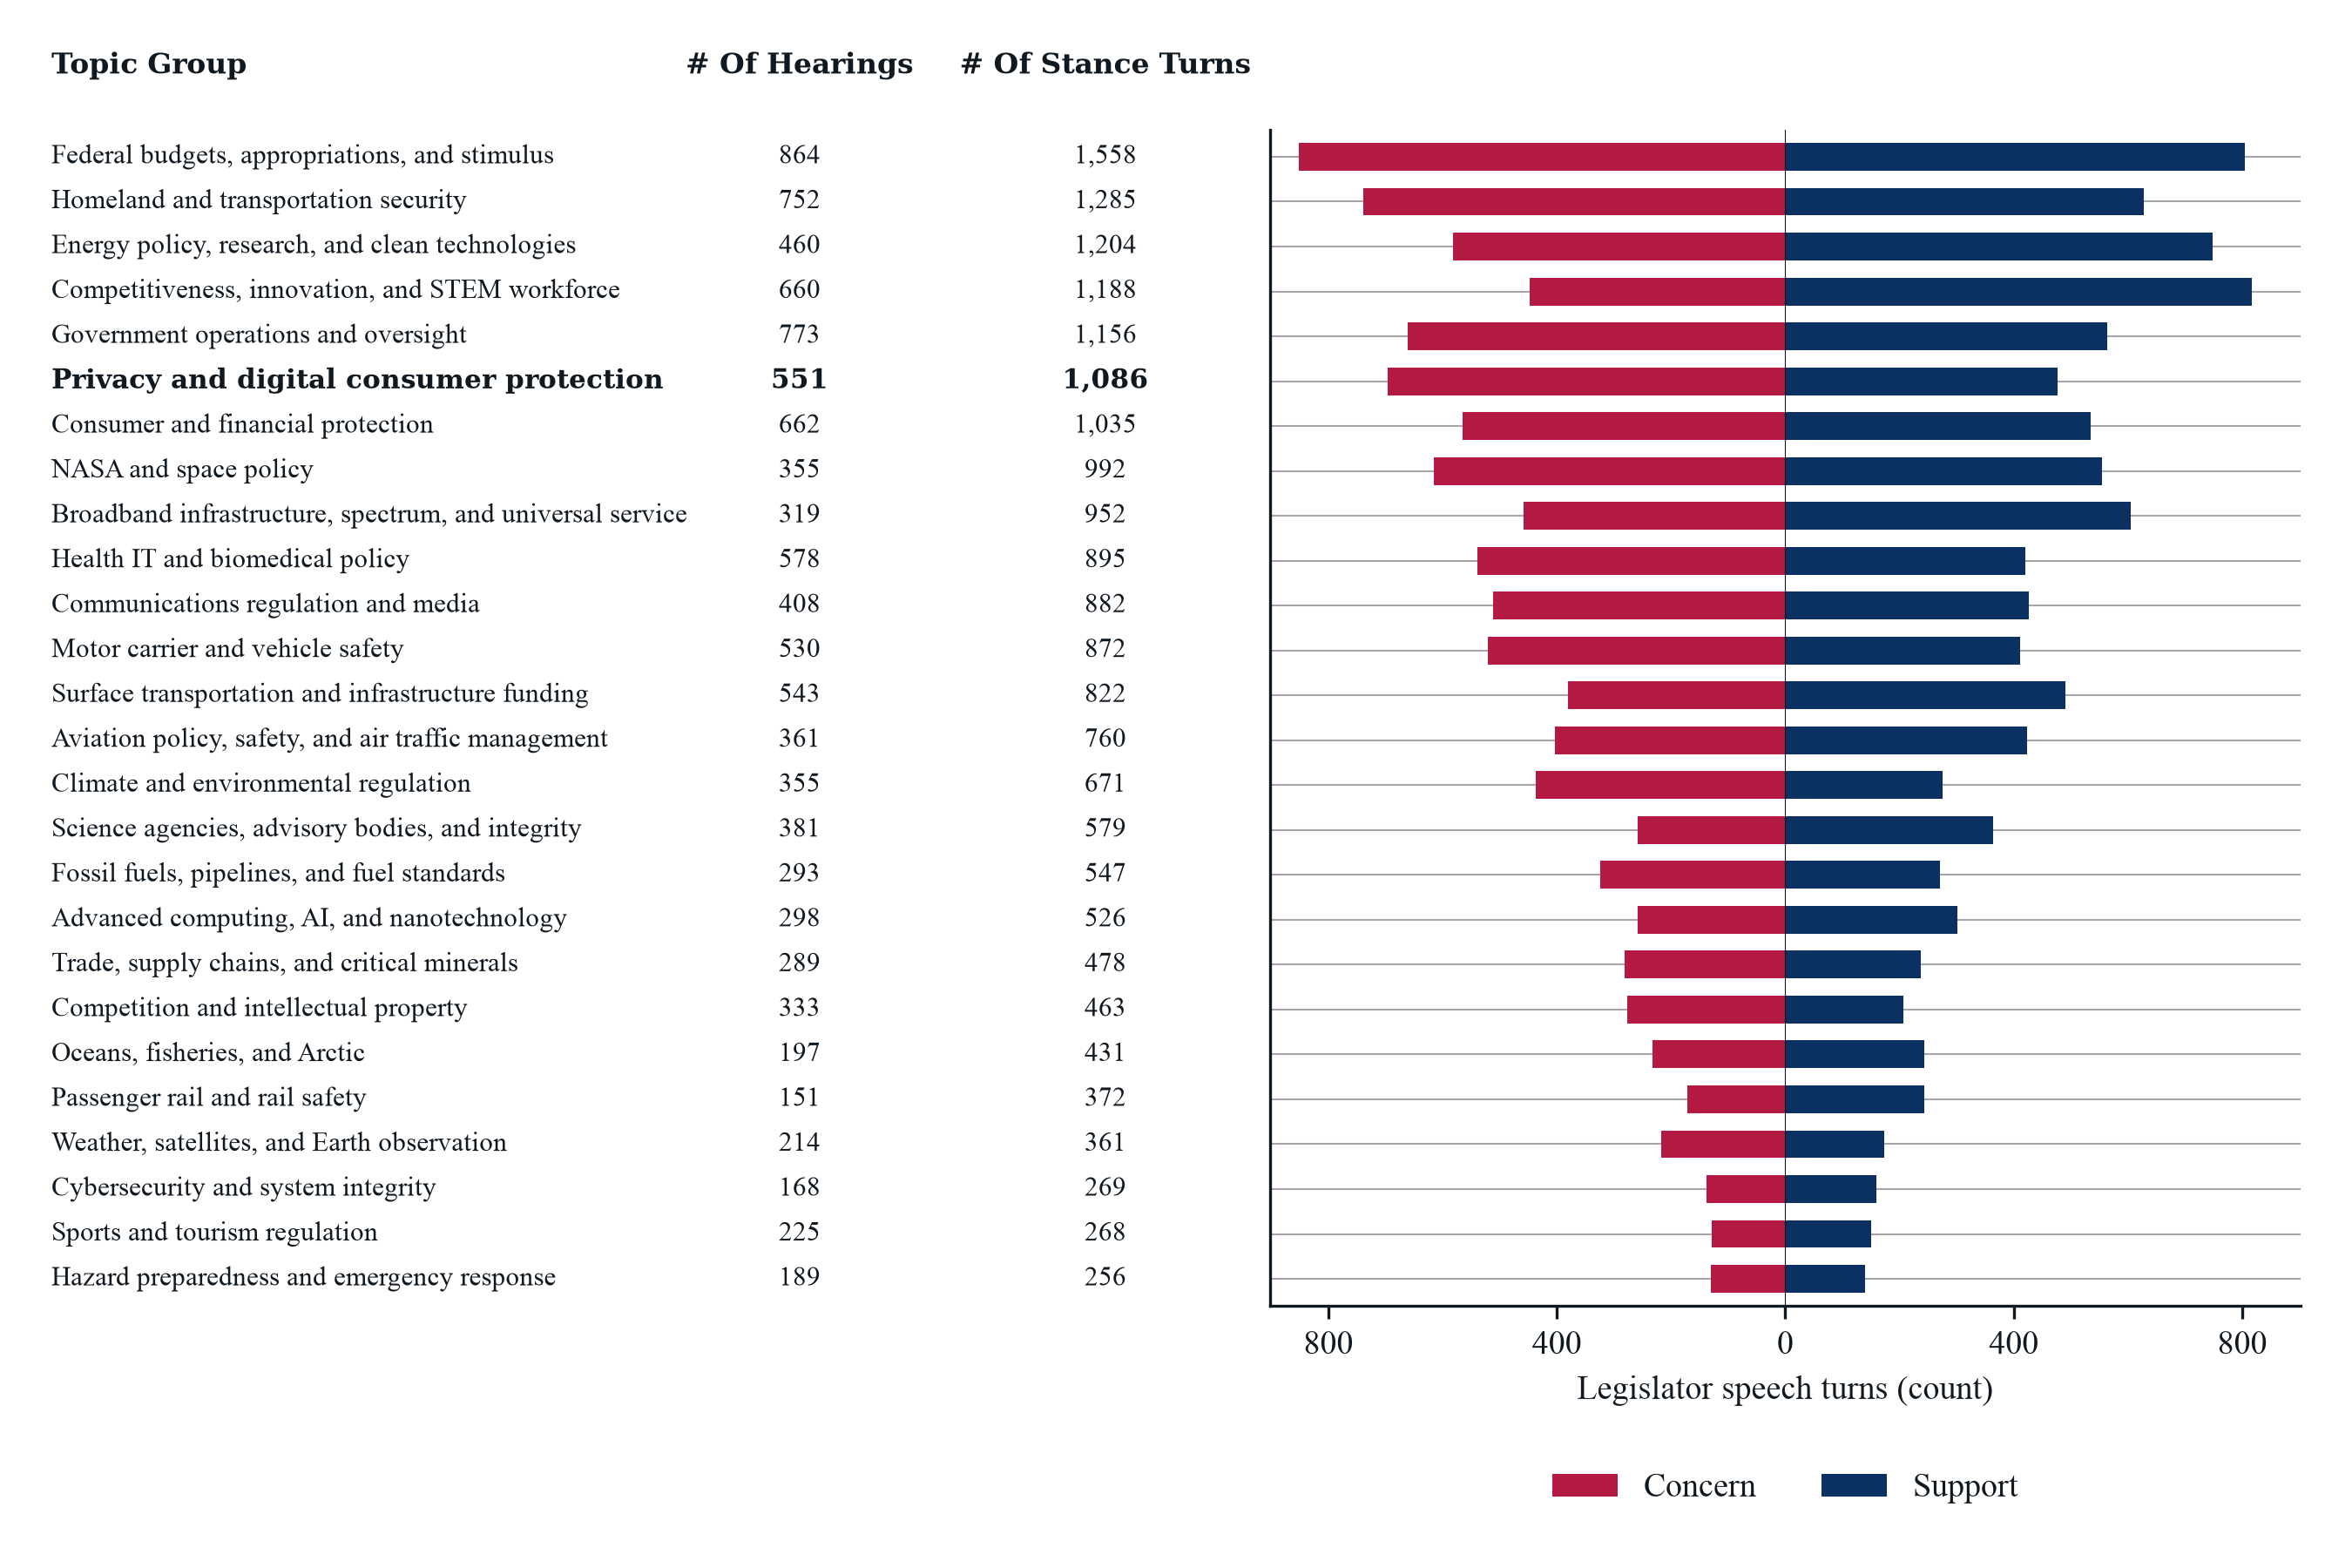

*Notes*: Sample: 2,206 House Science and Senate Commerce hearings, 1999–2025; 12,638 legislator speech turns with stance. Topic groups manually cluster extracted topics. Counts show distinct hearings and legislator speech turns expressing a stance on a group topic. Concern marks turns in which legislators express worry, criticism, or objection toward a topic, or urge its restriction, delay, or scrutiny. Support marks turns in which legislators endorse or advocate for a topic, or urge its adoption, funding, or expansion. Mixed-stance turns enter both bars but count once in totals.

*Source*: Extracted legislator stances and manual topic grouping.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.1/fig_select_volume_balance_groups


In [14]:
figure_name = "fig_select_volume_balance_groups"
figure_title = "Figure 1. Legislator Concern and Support by Topic Group"
figure, axis = plt.subplots()
positions = range(len(group_counts))
bar_height = 0.62
group_column = MARGIN_INCHES / FIGURE_WIDTH
hearing_column = 0.34
turn_column = 0.47
plot_left = 0.54
plot_right = 1 - MARGIN_INCHES / FIGURE_WIDTH
header_top = 1 - MARGIN_INCHES / FIGURE_HEIGHT
figure.subplots_adjust(left=plot_left, right=plot_right, top=header_top - 0.05, bottom=0.2)

axis.barh(
    positions, -group_counts["concern_turns"], height=bar_height, color=RED, label="Concern"
)
axis.barh(
    positions, group_counts["support_turns"], height=bar_height, color=BLUE, label="Support"
)
axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH)
axis.set_yticks(positions)
axis.set_ylim(len(group_counts) - 0.4, -0.6)
axis.set_xlabel("Legislator speech turns (count)")
axis.tick_params(axis="y", left=False, labelleft=False)
axis.spines[["top", "right"]].set_visible(False)

row_transform = blended_transform_factory(figure.transFigure, axis.transData)
for position, row in enumerate(group_counts.itertuples(index=False)):
    row_style = BOLD_TEXT if row.group == "Privacy and digital consumer protection" else {}
    axis.text(
        group_column, position, row.group, transform=row_transform,
        ha="left", va="center", fontsize=7.5, clip_on=False, **row_style,
    )
    axis.text(
        hearing_column, position, f"{row.n_hearings:,}", transform=row_transform,
        ha="center", va="center", fontsize=7.5, clip_on=False, **row_style,
    )
    axis.text(
        turn_column, position, f"{row.stance_turns:,}", transform=row_transform,
        ha="center", va="center", fontsize=7.5, clip_on=False, **row_style,
    )

figure.text(
    group_column, header_top, "Topic Group", ha="left", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    hearing_column, header_top, "# Of Hearings", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    turn_column, header_top, "# Of Stance Turns", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)

maximum_count = group_counts[["concern_turns", "support_turns"]].to_numpy().max()
axis_limit = max(1, maximum_count) * 1.06
axis.set_xlim(-axis_limit, axis_limit)
tick_positions = MaxNLocator(nbins=6, integer=True).tick_values(-axis_limit, axis_limit)
tick_positions = tick_positions[abs(tick_positions) <= axis_limit]
axis.set_xticks(tick_positions, labels=[f"{abs(int(value)):,}" for value in tick_positions])

legend = figure.legend(
    loc="lower center",
    bbox_to_anchor=((plot_left + plot_right) / 2, MARGIN_INCHES / FIGURE_HEIGHT),
    bbox_transform=figure.transFigure, ncol=2, frameon=False, borderaxespad=0,
)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
legend_top = legend.get_window_extent(renderer).y1
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (legend_top + MARGIN_INCHES * figure.dpi - label_bottom) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"Sample: {sample_records['packageId'].nunique():,} House Science and Senate Commerce "
    f"hearings, {YEAR_MIN}–{YEAR_MAX}; {len(unique_speech_turns):,} legislator speech turns with stance. "
    "Topic groups manually cluster extracted topics. Counts show distinct hearings and "
    "legislator speech turns expressing a stance on a group topic. "
    "Concern marks turns in which legislators express worry, criticism, or objection toward "
    "a topic, or urge its restriction, delay, or scrutiny. Support marks turns in which "
    "legislators endorse or advocate for a topic, or urge its adoption, funding, or expansion. "
    "Mixed-stance turns enter both bars but count once in totals."
)
figure_source = "Extracted legislator stances and manual topic grouping."
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {figure_source}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")